## Analyzing the Population and Land Area in European Countries
# Gavin Hockin
# 11/15/26

## European Countries
https://jsonlint.com/datasets/european-countries 
I chose this dataset to compare European countries with a larger land to see if they have a larger population because of it.

Each row contains basic information of the country like the name, area, population, currency, and more. 

I will mainly be focusing on the area and population of the country.

Hypothesis: There is a positive relationship between land area and population, meaning countries with more land in this dataset will tend to have more people. With that being said, I will also expect that when countries are grouped by size (small, medium, and large), the larger-area groups will have higher median populations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

df = pd.read_json("european-countries.json")
df = pd.json_normalize(df["countries"])
df.head()

,name,code,capital,population,area_km2,eu_member,currency
0,Albania,AL,Tirana,2877797,28748.0,False,ALL
1,Andorra,AD,Andorra la Vella,77265,468.0,False,EUR
2,Austria,AT,Vienna,9006398,83879.0,True,EUR
3,Belarus,BY,Minsk,9449323,207600.0,False,BYN
4,Belgium,BE,Brussels,11589623,30528.0,True,EUR


In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (43, 7)

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        43 non-null     str    
 1   code        43 non-null     str    
 2   capital     43 non-null     str    
 3   population  43 non-null     int64  
 4   area_km2    43 non-null     float64
 5   eu_member   43 non-null     bool   
 6   currency    43 non-null     str    
dtypes: bool(1), float64(1), int64(1), str(4)
memory usage: 3.1 KB


In [4]:
df.describe()

,population,area_km2
count,4.300000e+01,43.000000
mean,1.395311e+07,139351.777674
std,2.104855e+07,169615.548387
min,8.250000e+02,0.440000
25%,1.982568e+06,29638.000000
50%,5.540720e+06,65300.000000
75%,1.056602e+07,222998.500000
max,8.378394e+07,643801.000000


I will now clean and transform the data as needed so we can focus on the area and population. We need these data points to be clean to be able to accurately read and analyze the data.

In [6]:
# Used Claude AI to help me with this code

df_clean = df.copy()

# Changing the population to millions so it is easier to read. I used Claude AI to help me with this code.
df_clean["population_millions"] = df_clean["population"] / 1_000_000

# Categorical variable: split countries into three equal sized groups by land area
df_clean["area_group"] = pd.qcut(
    df_clean["area_km2"],
    q=3,
    labels = ["Small", "Medium", "Large"]
)

df_clean.head()

,name,code,capital,population,area_km2,eu_member,currency,population_millions,area_group
0,Albania,AL,Tirana,2877797,28748.0,False,ALL,2.877797,Small
1,Andorra,AD,Andorra la Vella,77265,468.0,False,EUR,0.077265,Small
2,Austria,AT,Vienna,9006398,83879.0,True,EUR,9.006398,Medium
3,Belarus,BY,Minsk,9449323,207600.0,False,BYN,9.449323,Large
4,Belgium,BE,Brussels,11589623,30528.0,True,EUR,11.589623,Small


In [7]:
# Confirm the groups and see where the cutoffs fall
print(df_clean["area_group"].value_counts().sort_index())
print()
print(df_clean.groupby("area_group", observed=True)["area_km2"].agg(["min", "max"]))

area_group
Small     15
Medium    14
Large     14
Name: count, dtype: int64

                  min       max
area_group                     
Small            0.44   41543.0
Medium       43094.00  103000.0
Large       110879.00  643801.0


No rows were removed or changed from the original data. 2 columns were added: population_millions and area_group.

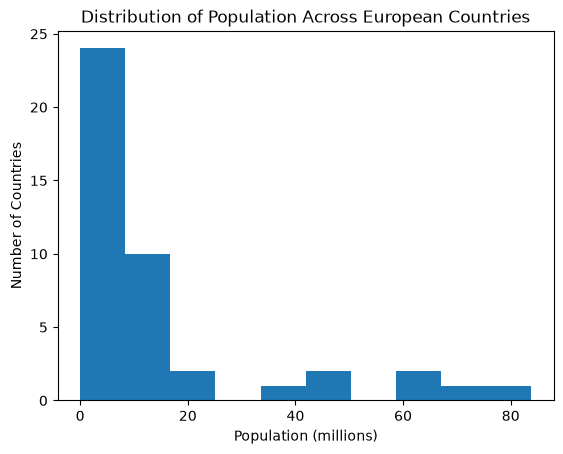

In [8]:
# Creating a histogram using the new population_millions column
plt.hist(df_clean["population_millions"], bins=10)

plt.xlabel("Population (millions)")
plt.ylabel("Number of Countries")
plt.title("Distribution of Population Across European Countries")
plt.show()

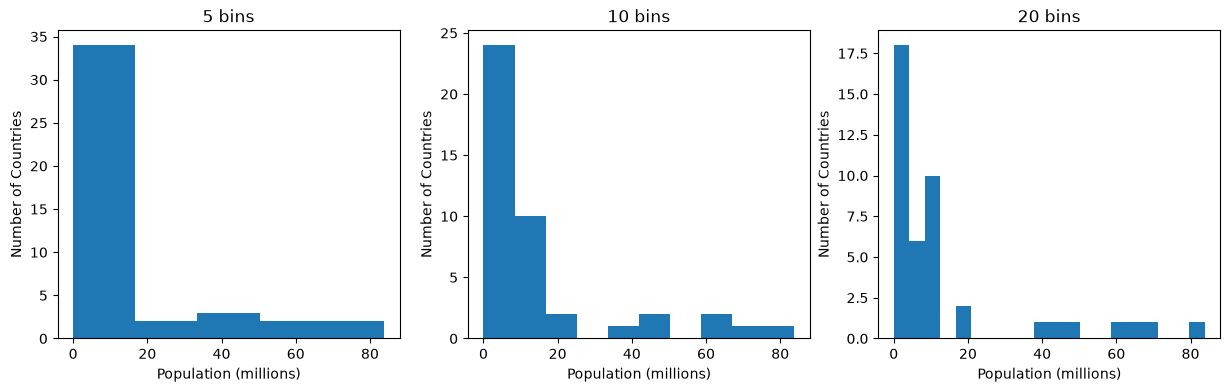

In [9]:
# Now changing the bin number to see how it affects the visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, n_bins in zip(axes, [5, 10, 20]):
    ax.hist(df_clean["population_millions"], bins=n_bins)
    ax.set_title(f"{n_bins} bins")
    ax.set_xlabel("Population (millions)")
    ax.set_ylabel("Number of Countries")

plt.show()

What does this figure show and why it is useful: The histogram shows how many European countries fall into each population range. It’s a good first look at one variable because it shows the shape, center, and spread of the data, which matters before running any analysis.

What does the distribution look like: The distribution is strongly right-skewed. Most countries have relatively small populations, and a few have very large ones. The median population is about 5.5 million, while the mean is about 14.0 million, and the mean is pulled up by the largest countries.

Are there any unusual values or patterns: Yes. Six countries have more than 40 million people: Germany (about 83.8 million), the United Kingdom (67.9 million), France (65.3 million), Italy (60.5 million), Spain (46.8 million), and Ukraine (43.7 million). These form a long tail and are far from the typical country. At the other end, 9 countries have fewer than 1 million people, including microstates like Vatican City (825 people), Monaco, and San Marino. There is also a gap in the middle of the distribution, with at least one empty bin between the mid-sized countries and the largest ones. These values are real, not errors, so I kept them.

How does my choice of bins affect the visualization: The bins change the story. With 5 bins, 34 of the 43 countries land in the first bar, which hides almost all the detail about small and mid-sized countries. With 20 bins, the shape is more detailed, but many bins are empty or have only one country, so the chart looks choppy. 10 bins was the best balance for me: it shows the heavy concentration of small countries and the long tail without being cluttered. Because the data is skewed, no bin width is perfect, and a log scale could help later.

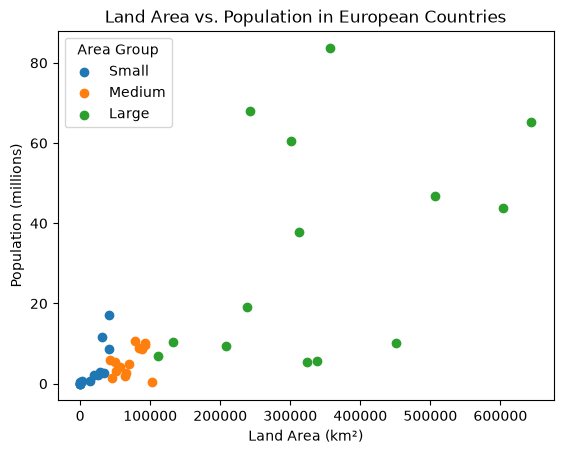

In [10]:
# Creating a scatter plot
colors = {"Small": "tab:blue", "Medium": "tab:orange", "Large": "tab:green"}

for group in ["Small", "Medium", "Large"]:
    subset = df_clean[df_clean["area_group"] == group]
    plt.scatter(
        subset["area_km2"],
        subset["population_millions"],
        color=colors[group],
        label=group
    )

plt.xlabel("Land Area (km²)")
plt.ylabel("Population (millions)")
plt.title("Land Area vs. Population in European Countries")
plt.legend(title="Area Group")
plt.show()

This scatter plot shows each European country’s land area (x-axis) and population (y-axis), colored by area group, to reveal whether the two variables move together. There is a positive relationship: countries with larger areas tend to have larger populations. Although they have a positive relationship, you can see that the large group is spread out the further left you go on the graph. The small and medium groups are pretty close together and well correlated. 

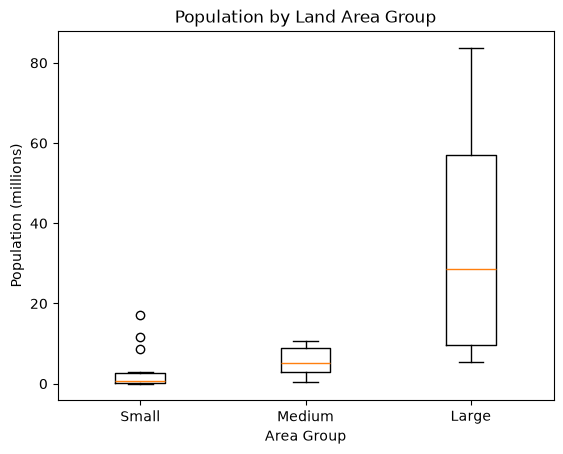

In [11]:
# Create the box plot
# Split population into one list per area group
small = df_clean[df_clean["area_group"] == "Small"]["population_millions"]
medium = df_clean[df_clean["area_group"] == "Medium"]["population_millions"]
large = df_clean[df_clean["area_group"] == "Large"]["population_millions"]

plt.boxplot(
    [small, medium, large],
    tick_labels=["Small", "Medium", "Large"]
)

plt.xlabel("Area Group")
plt.ylabel("Population (millions)")
plt.title("Population by Land Area Group")
plt.show()

This boxplot compares the population distribution of Small, Medium, and Large countries, which makes it easy to compare medians and spread. The median population rises sharply with area, from about 0.6 million (Small) to 5.2 million (Medium) to 28.5 million (Large). The Large group also has by far the widest spread, with a middle 50% range of roughly 9.6 to 57 million, while the Small group is tightly packed near zero. The Small group has a few high outliers though. 

For part 3, I was stuck on a lot of the code to be able to complete this part. I again used Claude AI to help me improve these visualizations. 

In [12]:
# Shared Style Setup

from matplotlib.lines import Line2D

# Apply a built-in style sheet and set readable font sizes
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12
})

# Same colors for the same groups in every figure
group_colors = {"Small": "#4C78A8", "Medium": "#F58518", "Large": "#54A24B"}
main_color = "#6B7A8F"   # neutral color for the histogram (all countries)
ref_color = "#C0392B"    # reference lines

# Tick positions/labels for log-scale population axes
pop_ticks = [0.001, 0.01, 0.1, 1, 10, 100]
pop_labels = ["0.001", "0.01", "0.1", "1", "10", "100"]

def clean_axes(ax):
    """Remove top/right borders and soften the gridlines."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)

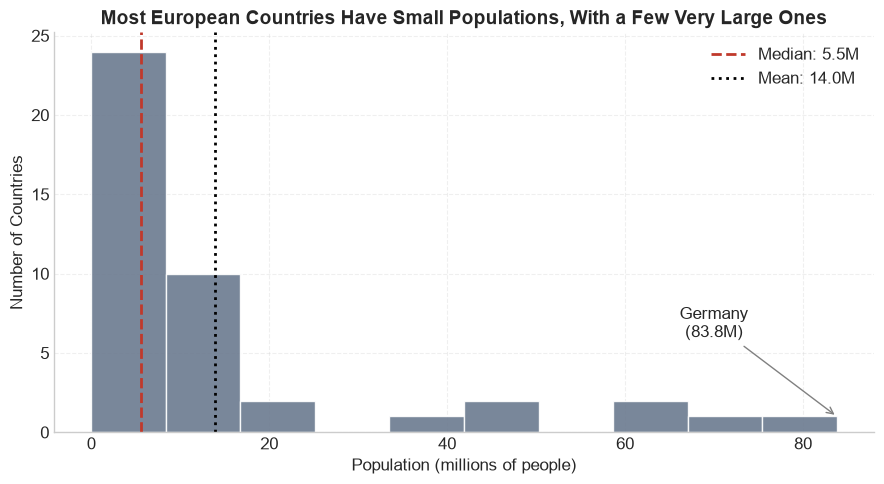

In [13]:
# Improved Histogram

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(df_clean["population_millions"], bins=10,
        color=main_color, edgecolor="white", alpha=0.9)

# Reference lines for the median and mean
median_pop = df_clean["population_millions"].median()
mean_pop = df_clean["population_millions"].mean()
ax.axvline(median_pop, color=ref_color, linestyle="--", linewidth=2,
           label=f"Median: {median_pop:.1f}M")
ax.axvline(mean_pop, color="black", linestyle=":", linewidth=2,
           label=f"Mean: {mean_pop:.1f}M")

# Annotate the largest country
ax.annotate("Germany\n(83.8M)", xy=(83.8, 1), xytext=(70, 6), ha="center",
            arrowprops=dict(arrowstyle="->", color="gray"))

ax.set_xlabel("Population (millions of people)")
ax.set_ylabel("Number of Countries")
ax.set_title("Most European Countries Have Small Populations, With a Few Very Large Ones")
ax.legend()
clean_axes(ax)
plt.tight_layout()
plt.show()

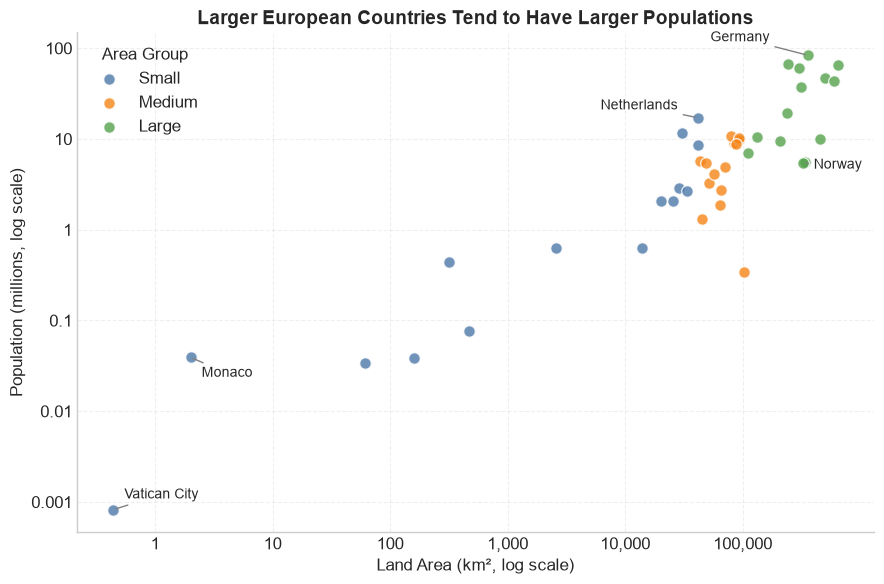

In [14]:
# Improved Scatter Plot

fig, ax = plt.subplots(figsize=(9, 6))

for group in ["Small", "Medium", "Large"]:
    s = df_clean[df_clean["area_group"] == group]
    ax.scatter(s["area_km2"], s["population_millions"],
               color=group_colors[group], alpha=0.8, s=70,
               edgecolor="white", label=group)

# Log scales spread out the crowded small countries
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(["1", "10", "100", "1,000", "10,000", "100,000"])
ax.set_yticks(pop_ticks)
ax.set_yticklabels(pop_labels)

# Label a few notable countries (name: text offset in points)
labels = {"Germany": (-70, 10), "Vatican City": (8, 8), "Norway": (8, -4),
          "Netherlands": (-70, 6), "Monaco": (8, -14)}
for name, offset in labels.items():
    r = df_clean[df_clean["name"] == name].iloc[0]
    ax.annotate(name, xy=(r["area_km2"], r["population_millions"]),
                xytext=offset, textcoords="offset points", fontsize=10,
                arrowprops=dict(arrowstyle="-", color="gray"))

ax.set_xlabel("Land Area (km², log scale)")
ax.set_ylabel("Population (millions, log scale)")
ax.set_title("Larger European Countries Tend to Have Larger Populations")
ax.legend(title="Area Group")
clean_axes(ax)
plt.tight_layout()
plt.show()

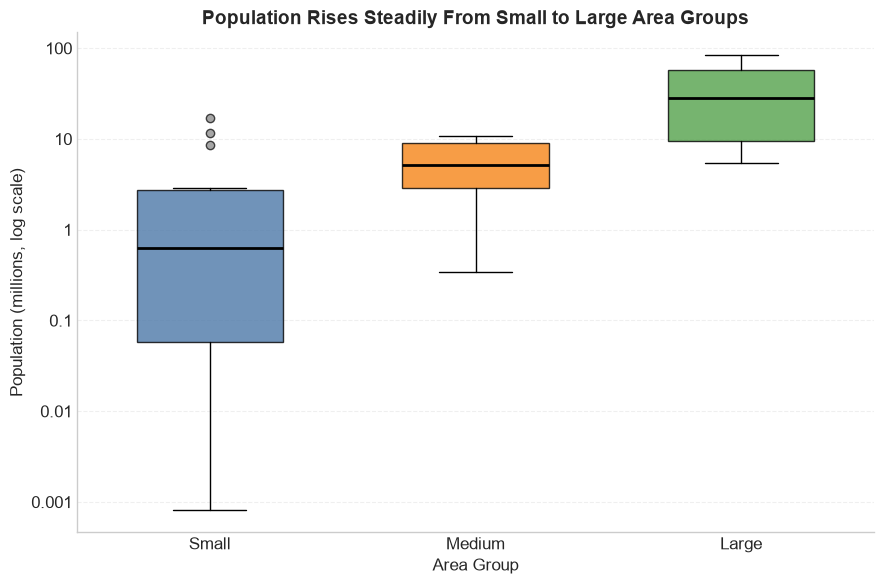

In [15]:
# Improved Boxplot

order = ["Small", "Medium", "Large"]
data = [df_clean[df_clean["area_group"] == g]["population_millions"] for g in order]

fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(data, tick_labels=order, patch_artist=True, widths=0.55,
                medianprops=dict(color="black", linewidth=2),
                flierprops=dict(marker="o", markerfacecolor="gray",
                                markersize=6, alpha=0.7))

# Match box colors to the scatter plot
for patch, g in zip(bp["boxes"], order):
    patch.set_facecolor(group_colors[g])
    patch.set_alpha(0.8)

ax.set_yscale("log")
ax.set_yticks(pop_ticks)
ax.set_yticklabels(pop_labels)

ax.set_xlabel("Area Group")
ax.set_ylabel("Population (millions, log scale)")
ax.set_title("Population Rises Steadily From Small to Large Area Groups")
clean_axes(ax)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Histogram: I added dashed and dotted reference lines for the median (5.5M) and mean (14.0M), plus an annotation for Germany. The gap between the two lines shows the skew immediately, and the annotation points out the largest value. I also changed the title to state the main finding instead of just naming the variable.

Scatter plot: I switched both axes to a log scale and replaced the tick labels with plain numbers. In the original, most small countries were crowded into the lower left corner, and the log scale spreads them out so the positive relationship is easier to see. I also added transparency, white marker edges, and labels for notable countries like Germany, Norway, Monaco, and Vatican City.

Boxplot: I used a log scale on the y-axis, the same group colors as the scatter plot, and a thick black median line. The log scale makes the small group’s boxes readable, since its populations range from under 1,000 to over 17 million, and the thick median line makes the steady rise from Small to Large easy to compare. The titles of all three figures now state the takeaway, which helps readers understand the point of each figure.

In [17]:
# Option B: Correlation and OLS Regression
# Claude AI suggested that I import numpy to help me with the correlation and regression model

from statsmodels.formula.api import ols
import numpy as np

# Independent variable (X): land area in km²
# Dependent variable (Y): population in millions
correlation = df_clean["area_km2"].corr(df_clean["population_millions"])
print("Correlation between area and population:", round(correlation, 3))

Correlation between area and population: 0.729


In [18]:
model_a = ols("population_millions ~ area_km2", data=df_clean).fit()
print(model_a.summary())

                             OLS Regression Results                            
Dep. Variable:     population_millions   R-squared:                       0.532
Model:                             OLS   Adj. R-squared:                  0.520
Method:                  Least Squares   F-statistic:                     46.55
Date:                 Sun, 15 Nov 2026   Prob (F-statistic):           2.93e-08
Time:                         17:06:46   Log-Likelihood:                -175.21
No. Observations:                   43   AIC:                             354.4
Df Residuals:                       41   BIC:                             357.9
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.3434      2.891      0.46

In [19]:
print("Intercept:", model_a.params["Intercept"])
print("Slope:", model_a.params["area_km2"])
print("P-value (slope):", model_a.pvalues["area_km2"])
print("R-squared:", model_a.rsquared)

Intercept: 1.3433564954471977
Slope: 9.048865842953918e-05
P-value (slope): 2.9316313936470713e-08
R-squared: 0.5317104881009243


In [20]:
df_clean["log_area"] = np.log10(df_clean["area_km2"])
df_clean["log_population"] = np.log10(df_clean["population"])

model_log = ols("log_population ~ log_area", data=df_clean).fit()

print("Slope:", model_log.params["log_area"])
print("P-value (slope):", model_log.pvalues["log_area"])
print("R-squared:", model_log.rsquared)

Slope: 0.6867714799857367
P-value (slope): 1.843732011566454e-17
R-squared: 0.8316985325490369


I used land area (km²) as the independent variable and population (millions) as the dependent variable. The correlation is 0.73, and the regression slope is statistically significant (p ≈ 2.9 × 10⁻⁸): each additional 100,000 km² is associated with roughly 9 million more people, and area explains about 53% of the variation in population (R² = 0.53), which supports my hypothesis. A log-log model fits much better (R² = 0.83), showing the relationship is clearer in proportional terms. Limitations include residuals that are not normally distributed (Jarque-Bera p < 0.001, driven by outliers like Germany and the Nordic countries), data that covers nearly all of Europe instead of a random sample, and the fact that correlation does not show that area causes population.

What I learned and whether my hypothesis was supported: Larger European countries tend to have larger populations, which supports my hypothesis. The correlation was 0.73, the regression slope was significant (p ≈ 2.9 × 10⁻⁸), and median population rose from about 0.6 million (Small) to 5.2 million (Medium) to 28.5 million (Large). Area alone doesn’t explain everything, though: it accounts for about 53% of the variation in population, and countries like Germany, the UK, and the Nordic countries sit far from the trend.

Most effective visualization: The log-scale scatter plot was the most effective, because it shows the relationship directly, spreads out the crowded small countries, and uses color and labels to highlight groups and notable countries. The statistical analysis added something the plots didn’t make obvious: the log-log slope of 0.69 is below 1, meaning population grows more slowly than area, so larger countries tend to be less densely populated. It also showed the log model fits far better (R² = 0.83 vs. 0.53).

Limitations and next steps: The dataset has only 43 countries at a single point in time, covers nearly all of Europe instead of a random sample, and leaves out some large countries such as Russia and Turkey. The size groups were built from area, so the boxplot isn’t an independent test, and the residuals were not normally distributed. My analysis can’t capture climate, terrain, urbanization, or economic history, which likely explain why some countries are far from the trend. Adding variables such as GDP, urban share, or habitable land, comparing multiple years, or re-running the analysis without the microstates would improve the investigation.